# Exploratory Data Analysis (EDA) — From Raw Data to Meaningful Insights

**Tutorial dataset:** Netflix Movies and TV Shows  





## 1. Setup

We will use:
- **Pandas** for data loading, cleaning and tabular analysis
- **NumPy** for numerical operations
- **Matplotlib** for visualization
- **Seaborn** for polished statistical plots


In [ ]:
# Install KaggleHub in Colab
!pip -q install kagglehub

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load the Netflix dataset



In [ ]:
import kagglehub

# Download the public dataset
dataset_dir = kagglehub.dataset_download("shivamb/netflix-shows")
print("Dataset downloaded to:", dataset_dir)

# Find the CSV file automatically
csv_files = glob.glob(os.path.join(dataset_dir, "**", "*.csv"), recursive=True)
print("CSV files found:", csv_files)

# Load the first CSV
df = pd.read_csv(csv_files[0])
df.head()


Using Colab cache for faster access to the 'netflix-shows' dataset.
Dataset downloaded to: /kaggle/input/netflix-shows
CSV files found: ['/kaggle/input/netflix-shows/netflix_titles.csv']


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages hi..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Na...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether ..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Sal...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his..."
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at t..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pi...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies",In a city of coaching centers known to train India’s finest collegiate minds...


## 3. First look: shape, columns and data types

Never jump directly to charts.

Start with:
1. Number of rows and columns
2. Column names
3. Data types
4. A few records

This tells us what kind of analysis is possible.


In [ ]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())


Shape: (8807, 12)

Columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data types:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

First 5 rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages hi..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Na...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether ..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Sal...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his..."
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at t..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pi...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies",In a city of coaching centers known to train India’s finest collegiate minds...


## 4. Can we trust the data?

A dataset can look clean while still containing:
- missing values
- duplicate records
- inconsistent data types
- inconsistent categories
- impossible or suspicious values

We inspect all of these before drawing conclusions.


In [ ]:
# Missing values
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)

missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct.round(2)
})

display(missing_report)

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Unique values in important categorical fields
for col in ["type", "rating"]:
    if col in df.columns:
        print(f"\n{col} — {df[col].nunique(dropna=True)} unique values")
        print(df[col].value_counts(dropna=False).head(15))


,missing_count,missing_percent
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


Duplicate rows: 0

type — 2 unique values
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

rating — 17 unique values
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
Name: count, dtype: int64


## 5. Cleaning: decide, don't blindly fill

**Rule:** missing data is a question, not automatically a problem.

For this dataset:
- `date_added` is useful for time analysis, so we parse it.
- `duration` contains both minutes and seasons, so we keep it as text initially.
- We avoid inventing director/cast/country information.
- We remove exact duplicate rows if they exist.

We will create a cleaned copy rather than destroying the original.


In [ ]:
clean = df.copy()

# Remove exact duplicate rows
before = len(clean)
clean = clean.drop_duplicates().copy()
print(f"Removed {before - len(clean)} duplicate rows.")

# Parse date_added safely
clean["date_added"] = pd.to_datetime(clean["date_added"], errors="coerce")

# Standardize a few text fields
for col in ["type", "rating"]:
    if col in clean.columns:
        clean[col] = clean[col].astype("string").str.strip()

# Create a numeric year column for easier analysis
clean["release_year"] = pd.to_numeric(clean["release_year"], errors="coerce")

clean.info()


Removed 0 duplicate rows.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   object        
 1   type          8807 non-null   string        
 2   title         8807 non-null   object        
 3   director      6173 non-null   object        
 4   cast          7982 non-null   object        
 5   country       7976 non-null   object        
 6   date_added    8709 non-null   datetime64[ns]
 7   release_year  8807 non-null   int64         
 8   rating        8803 non-null   string        
 9   duration      8804 non-null   object        
 10  listed_in     8807 non-null   object        
 11  description   8807 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(8), string(2)
memory usage: 825.8+ KB


## 6. Drop or fill? A practical decision

There is no universal “best” treatment for missing values.

We can quantify the missingness and then choose a strategy based on the business/research question.

For a simple descriptive tutorial, we will:
- keep the main dataset intact;
- create analysis-specific subsets when a variable is required;
- use `"Unknown"` only when it is meaningful as a category.


In [ ]:
# Example: create a safe categorical version of country and rating
analysis_df = clean.copy()

for col in ["country", "rating"]:
    if col in analysis_df.columns:
        analysis_df[col] = analysis_df[col].fillna("Unknown")

# Missingness after our targeted treatment
display(
    analysis_df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
    .head(15)
)


,missing_count
director,2634
cast,825
date_added,98
duration,3
title,0
type,0
show_id,0
country,0
release_year,0
rating,0


## 7. Univariate analysis: interrogate one variable

Question:

> **What does this variable look like on its own?**

For categorical variables, frequency counts are often the best starting point.

Let's compare **Movies vs TV Shows**.


,count
type,
Movie,6131
TV Show,2676


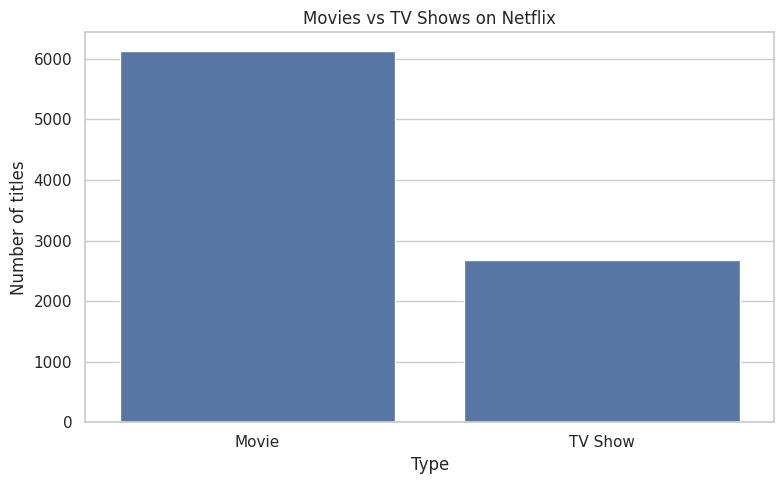

In [ ]:
type_counts = analysis_df["type"].value_counts()

display(type_counts.to_frame("count"))

plt.figure(figsize=(8, 5))
sns.countplot(data=analysis_df, x="type", order=type_counts.index)
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Type")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()


## 8. One variable isn't enough

A single count can answer **what exists**, but not necessarily **what is happening**.

Now we ask a relationship question:

> **How has the number of titles added to Netflix changed over time?**

This moves us from one-variable analysis toward a time trend.


,year_added,titles_added
4,2012,3
5,2013,10
6,2014,23
7,2015,73
8,2016,418
9,2017,1164
10,2018,1625
11,2019,1999
12,2020,1878
13,2021,1498


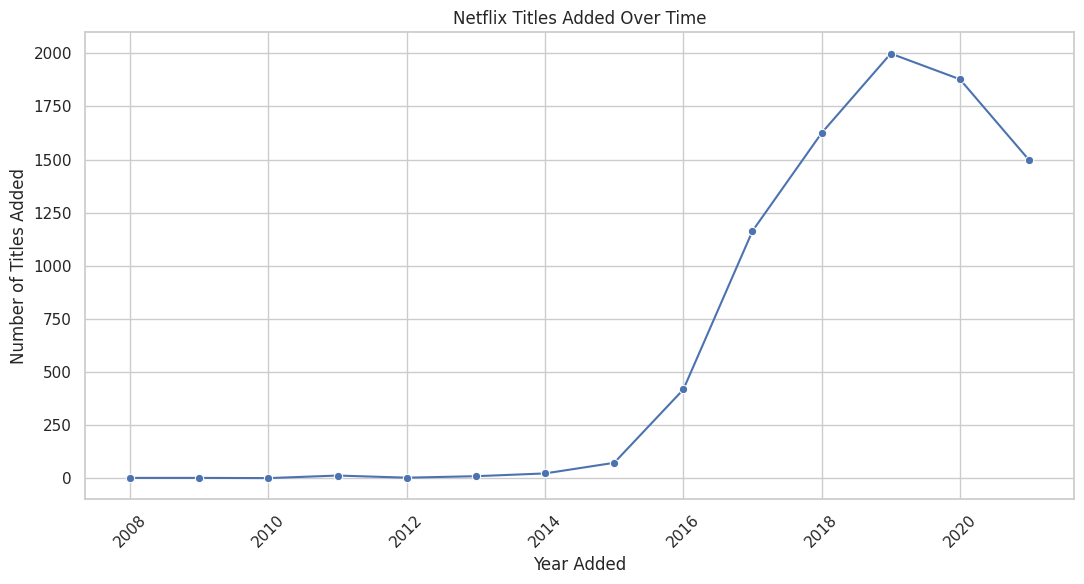

In [ ]:
added_by_year = (
    analysis_df.dropna(subset=["date_added"])
    .assign(year_added=lambda x: x["date_added"].dt.year)
    .groupby("year_added")
    .size()
    .reset_index(name="titles_added")
    .sort_values("year_added")
)

display(added_by_year.tail(10))

plt.figure(figsize=(11, 6))
sns.lineplot(data=added_by_year, x="year_added", y="titles_added", marker="o")
plt.title("Netflix Titles Added Over Time")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles Added")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 9. Hypothesis-driven investigation

Instead of making random graphs, start with a question.

Examples:
- **Q1:** What type of content dominates?
- **Q2:** Has Netflix added more content in recent years?
- **Q3:** Which countries contribute the most titles?
- **Q4:** Are Movies and TV Shows distributed differently across ratings?
- **Q5:** What can unusually long/short values tell us?

We will investigate these one at a time.


In [ ]:
# Q1: What type dominates?
type_share = (
    analysis_df["type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("percentage")
)

display(type_share.to_frame())

# Q2: Recent additions
recent = added_by_year[added_by_year["year_added"] >= added_by_year["year_added"].max() - 5]
display(recent)


,percentage
type,
Movie,69.62
TV Show,30.38


,year_added,titles_added
8,2016,418
9,2017,1164
10,2018,1625
11,2019,1999
12,2020,1878
13,2021,1498


## 10. From chart to insight: ratings

Let's compare the distribution of ratings for Movies and TV Shows.

**Important:** the chart is not the insight.  
The insight is the sentence we can defend from the chart.


type,Movie,TV Show
rating,,
TV-MA,2062,1145
TV-14,1427,733
R,797,2
TV-PG,540,323
PG-13,490,0
PG,287,0
TV-Y7,139,195
TV-Y,131,176
TV-G,126,94


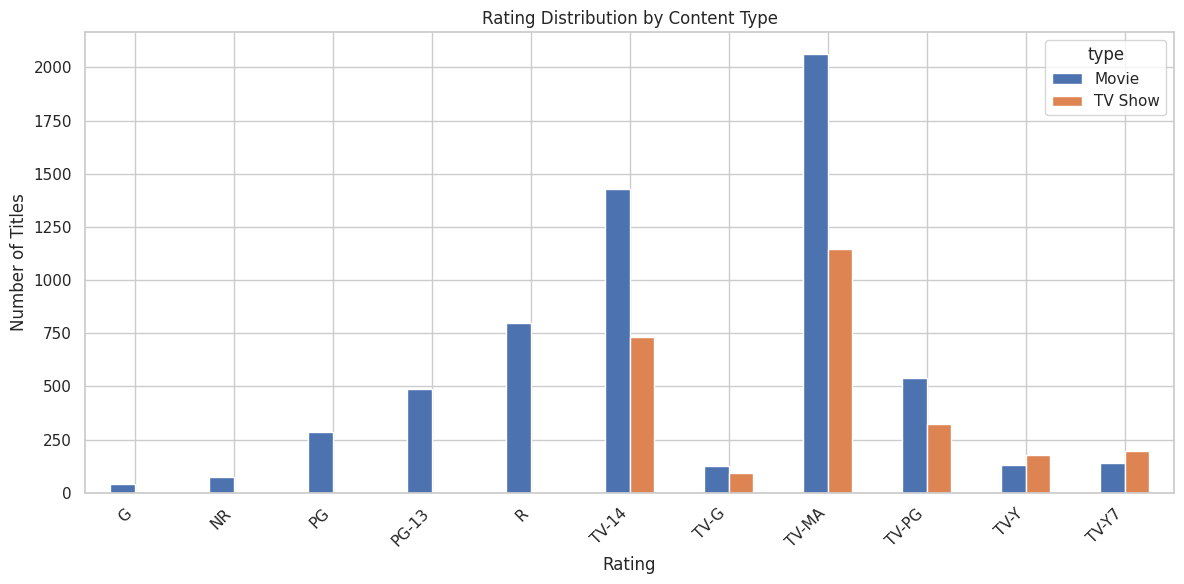

In [ ]:
rating_type = pd.crosstab(
    analysis_df["rating"],
    analysis_df["type"]
)

# Keep ratings with at least 20 total titles for readability
keep_ratings = rating_type.sum(axis=1)
rating_type = rating_type.loc[keep_ratings[keep_ratings >= 20].index]

display(rating_type.sort_values(by=rating_type.columns.tolist(), ascending=False).head(15))

rating_type.plot(kind="bar", figsize=(12, 6))
plt.title("Rating Distribution by Content Type")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 11. Geographic pattern: which countries appear most often?

The `country` field can contain multiple countries in a single cell, so a simple `value_counts()` would be misleading.

This is a classic EDA issue:

> **The data format can determine whether our analysis is valid.**

We split the multi-valued field and count individual country mentions.


,title_mentions
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


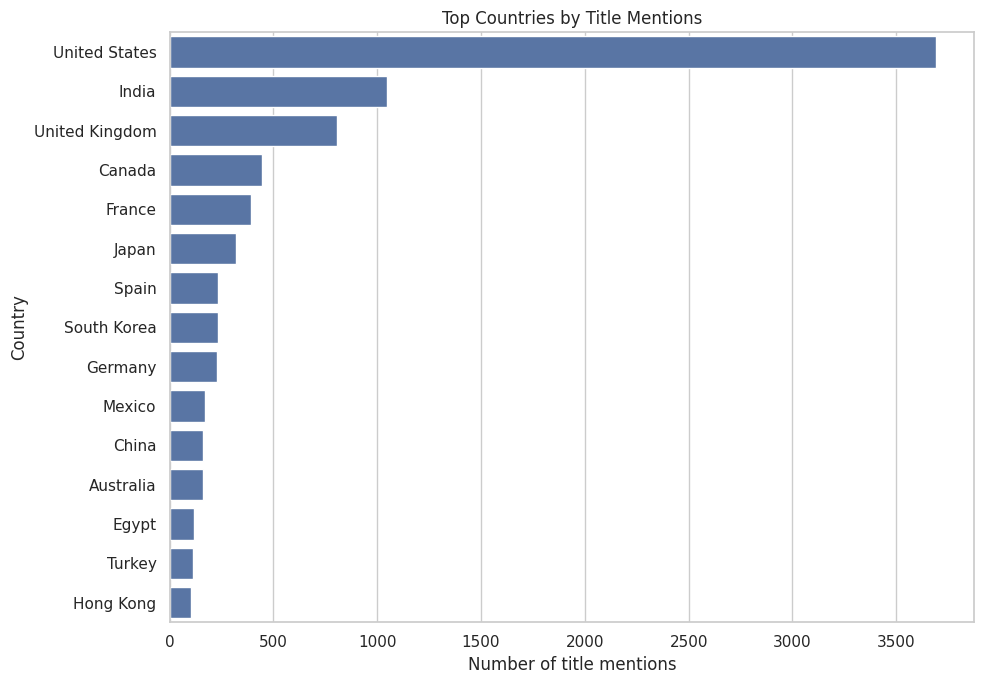

In [ ]:
country_series = (
    analysis_df["country"]
    .fillna("Unknown")
    .str.split(",")
    .explode()
    .str.strip()
)

country_counts = country_series[country_series != "Unknown"].value_counts().head(15)

display(country_counts.to_frame("title_mentions"))

plt.figure(figsize=(10, 7))
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title("Top Countries by Title Mentions")
plt.xlabel("Number of title mentions")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


## 12. Duration: turn text into an analyzable variable

`duration` mixes two concepts:
- Movie → minutes
- TV Show → seasons

We should **not** put both into one numeric column.

Instead, create:
- `duration_value`
- `duration_unit`

This is a good example of feature engineering during EDA.


In [ ]:
duration_parts = analysis_df["duration"].fillna("").str.extract(
    r"(?P<duration_value>\d+)\s*(?P<duration_unit>min|Season|Seasons)",
    expand=True
)

analysis_df["duration_value"] = pd.to_numeric(
    duration_parts["duration_value"], errors="coerce"
)
analysis_df["duration_unit"] = duration_parts["duration_unit"]

display(
    analysis_df[["type", "duration", "duration_value", "duration_unit"]]
    .head(10)
)

# Movie duration only
movie_duration = analysis_df.loc[
    (analysis_df["type"] == "Movie") &
    (analysis_df["duration_unit"] == "min"),
    "duration_value"
].dropna()

print("Movie duration — mean:", round(movie_duration.mean(), 1))
print("Movie duration — median:", round(movie_duration.median(), 1))
print("Movie duration — minimum:", movie_duration.min())
print("Movie duration — maximum:", movie_duration.max())


,type,duration,duration_value,duration_unit
0,Movie,90 min,90.0,min
1,TV Show,2 Seasons,2.0,Season
2,TV Show,1 Season,1.0,Season
3,TV Show,1 Season,1.0,Season
4,TV Show,2 Seasons,2.0,Season
5,TV Show,1 Season,1.0,Season
6,Movie,91 min,91.0,min
7,Movie,125 min,125.0,min
8,TV Show,9 Seasons,9.0,Season
9,Movie,104 min,104.0,min


Movie duration — mean: 99.6
Movie duration — median: 98.0
Movie duration — minimum: 3.0
Movie duration — maximum: 312.0


## 13. Outliers: error or discovery?

An unusually large or small value is **not automatically an error**.

For movie duration, we can use a boxplot to identify unusual observations.

Then investigate those rows before deciding what to do.


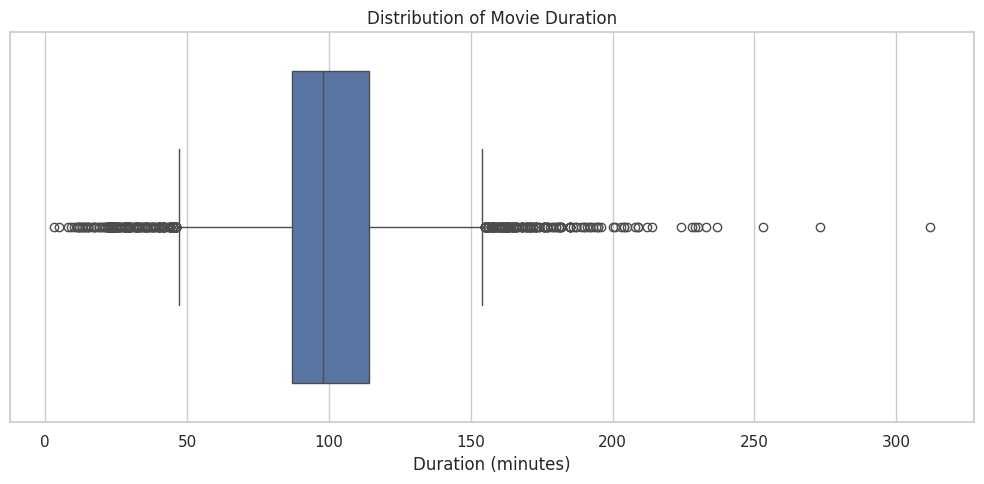

Potentially unusual long movies:


,title,release_year,duration,duration_value
4253,Black Mirror: Bandersnatch,2018,312 min,312.0
717,Headspace: Unwind Your Mind,2021,273 min,273.0
2491,The School of Mischief,1973,253 min,253.0
2487,No Longer kids,1979,237 min,237.0
2484,Lock Your Girls In,1982,233 min,233.0
2488,Raya and Sakina,1984,230 min,230.0
166,Once Upon a Time in America,1984,229 min,229.0
7932,Sangam,1964,228 min,228.0
1019,Lagaan,2001,224 min,224.0
4573,Jodhaa Akbar,2008,214 min,214.0


In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=movie_duration)
plt.title("Distribution of Movie Duration")
plt.xlabel("Duration (minutes)")
plt.tight_layout()
plt.show()

q1 = movie_duration.quantile(0.25)
q3 = movie_duration.quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

long_movies = analysis_df[
    (analysis_df["type"] == "Movie") &
    (analysis_df["duration_unit"] == "min") &
    (analysis_df["duration_value"] > upper)
][["title", "release_year", "duration", "duration_value"]].sort_values(
    "duration_value", ascending=False
)

print("Potentially unusual long movies:")
display(long_movies.head(15))


## 14. A compact EDA dashboard

EDA often becomes more useful when we bring complementary views together.

Here we create four quick summaries:
1. content type
2. titles added by year
3. ratings
4. movie duration

Use this as a **summary**, not as a substitute for asking questions.


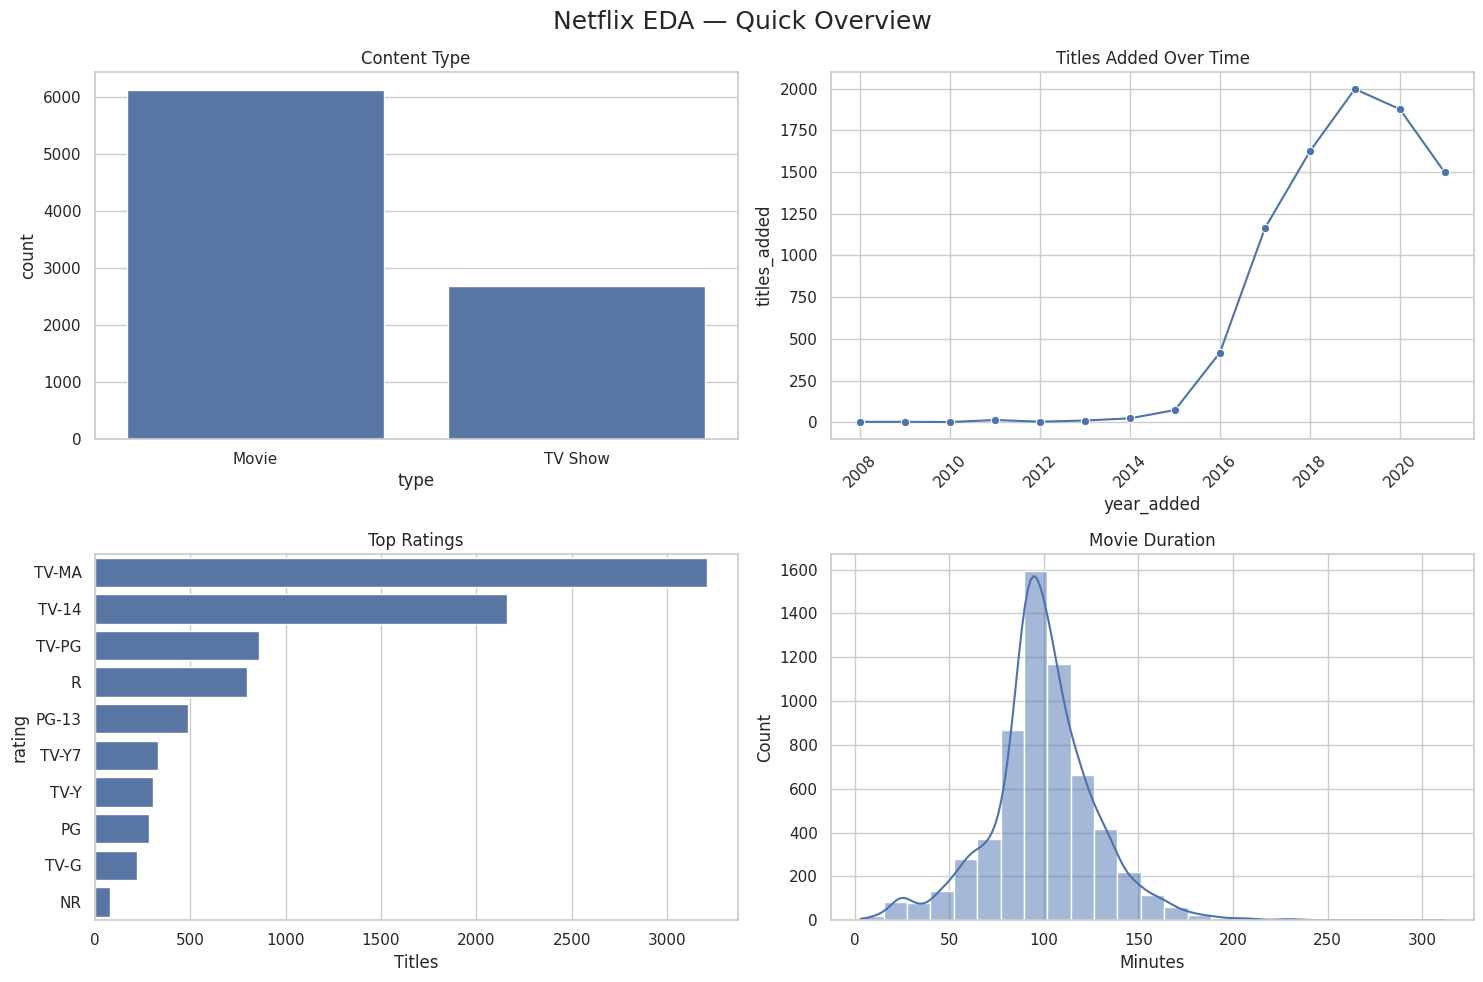

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.countplot(data=analysis_df, x="type", ax=axes[0, 0])
axes[0, 0].set_title("Content Type")

sns.lineplot(data=added_by_year, x="year_added", y="titles_added", marker="o", ax=axes[0, 1])
axes[0, 1].set_title("Titles Added Over Time")
axes[0, 1].tick_params(axis="x", rotation=45)

top_ratings = analysis_df["rating"].value_counts().head(10)
sns.barplot(x=top_ratings.values, y=top_ratings.index, ax=axes[1, 0])
axes[1, 0].set_title("Top Ratings")
axes[1, 0].set_xlabel("Titles")

sns.histplot(movie_duration, bins=25, kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Movie Duration")
axes[1, 1].set_xlabel("Minutes")

plt.suptitle("Netflix EDA — Quick Overview", fontsize=18)
plt.tight_layout()
plt.show()


## 15. Turn findings into statements

Use the **Chart → Analysis → Insight** framework.

### Chart
What do I literally see?

### Analysis
What comparison, pattern, concentration, trend or anomaly does it show?

### Insight
Why does this matter for the question or decision?

Avoid claims that the dataset cannot support.  
For example, **“more titles were added”** is descriptive; **“Netflix's strategy caused subscriber growth”** would require additional evidence.


In [ ]:
# A small automated summary to support your narration
total_titles = len(analysis_df)
movies = (analysis_df["type"] == "Movie").sum()
shows = (analysis_df["type"] == "TV Show").sum()

print(f"Total titles: {total_titles:,}")
print(f"Movies: {movies:,} ({movies/total_titles*100:.1f}%)")
print(f"TV Shows: {shows:,} ({shows/total_titles*100:.1f}%)")

if not added_by_year.empty:
    peak_row = added_by_year.loc[added_by_year["titles_added"].idxmax()]
    print(
        f"Peak year in this dataset: {int(peak_row['year_added'])} "
        f"with {int(peak_row['titles_added']):,} titles added."
    )

print(
    f"Median movie duration: {movie_duration.median():.0f} minutes "
    f"(based on {len(movie_duration):,} movies with usable duration data)."
)


Total titles: 8,807
Movies: 6,131 (69.6%)
TV Shows: 2,676 (30.4%)
Peak year in this dataset: 2019 with 1,999 titles added.
Median movie duration: 98 minutes (based on 6,128 movies with usable duration data).


# 5 things to remember

1. **Understand your data first.**
2. **Check data quality before analysis.**
3. **Choose visualizations based on the question.**
4. **Look for relationships, trends, distributions and anomalies.**
5. **Turn observations into defensible insights.**

**Good EDA doesn't just show data. It helps you understand what the data is saying — and what you should investigate next.**


In [ ]:
# Optional cleanup / reproducibility check
print("Final analysis dataset shape:", analysis_df.shape)
print("EDA workflow completed successfully.")


Final analysis dataset shape: (8807, 14)
EDA workflow completed successfully.
